# Permanência na UTI — protocolo ampliado de 24 horas

**70 variáveis no MIMIC; 65 no painel harmonizado com o eICU.**
Foram acrescentados PAS, AKI por creatinina, SOFA adaptado, arritmias, ausculta,
valvulopatia prévia e registro de cateterismo, mantendo `inputevents` e `outputevents`.

Para LOS >3,55 dias, o XGBoost ampliado obteve AUC **0.741**
no teste MIMIC; a MLP, **0.748**.
No eICU, o modelo harmonizado congelado obteve **0.666**
(XGBoost) e **0.626** (MLP).

Os resultados são exploratórios: a partição interna já foi consultada no desenvolvimento.
AKI não inclui diurese/RRT e o SOFA tem componentes adaptados e ausentes.
O experimento aproximado de Yang aparece separado, com população e janela diferentes.
As tabelas abaixo apresentam IC95%, calibração e contribuição das mudanças.


## 1. Método, fontes e execução

Adultos com IC, ainda na UTI em 24h; óbitos são mantidos. Eventos e disponibilidade
devem ser anteriores a 24h. FEVE preserva a janela −48h/+24h e não possui horário
de liberação de laudo. CID identifica retrospectivamente a coorte; não entra no modelo principal.

Divisão por paciente preservada da análise anterior. Busca de hiperparâmetros em
três partes agrupadas por paciente, exclusivamente no treino MIMIC. Imputação e
escala são ajustadas dentro das partes. O eICU recebe o modelo congelado.
Busca: oito candidatos XGBoost/classificação, quatro MLP e quatro por regressor;
semente 42. O limiar é escolhido no treino. AUC da busca não é validação independente.

Fontes locais: MIMIC-IV 3.1, eICU-CRD 2.0 e medidas estruturadas de Echo 1.0.1.
Código e mapeamentos: [protocolo ampliado](docs/protocolo_ampliado.md).
Artigo: [Yang et al.](https://doi.org/10.1093/eurjcn/zvaf075).

Para refazer a extração, siga o [README](README.md). A execução padrão abaixo lê
os resultados concluídos. Ative `REFAZER_EXPERIMENTOS` apenas para repetir os ajustes.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.metrics import roc_curve
from IPython.display import display
from experimentos_24h import ROOT, NOVAS, TODAS, rodar, diferenca_pareada

REFAZER_EXPERIMENTOS = False
if REFAZER_EXPERIMENTOS:
    rodar('tudo', bootstrap=500)
required = ['completo_ampliado/classificacao.csv','harmonizado/classificacao.csv',
            'ablacoes/comparacao.csv','yang_aproximado/comparacao.csv','auditoria_resumo.json']
missing = [str(ROOT/f) for f in required if not (ROOT/f).exists()]
if missing:
    raise FileNotFoundError('Execute experimentos_24h.py --etapa tudo. Faltam: '+', '.join(missing))
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
CORES = {'xgboost':'#2166ac','rede_neural':'#b35806'}
full = pd.read_csv(ROOT/'completo_ampliado/classificacao.csv')
harm = pd.read_csv(ROOT/'harmonizado/classificacao.csv')
quality = pd.read_csv(ROOT/'qualidade_variaveis.csv')
audit = json.loads((ROOT/'auditoria_resumo.json').read_text())
display(pd.DataFrame({b:audit[b] for b in ['mimic','eicu']}).T)
print('Unidade: uma estadia de UTI. Preditores:', audit['n_preditores_completo'], '/', audit['n_preditores_harmonizado'])


,estadias,pacientes,hospitais,prevalencia_355,prevalencia_7
mimic,21549.0,14655.0,1.0,0.406979,0.173001
eicu,13537.0,11169.0,198.0,0.403265,0.156165


Unidade: uma estadia de UTI. Preditores: 70 / 65


## 2. Cobertura e harmonização

Sem valor registrado não significa normal. Os indicadores de tratamento representam
evidência encontrada; os totais de volume/urina ficam ausentes quando não há medida.
FEVE, tipo de admissão, dose total de furosemida e NT-proBNP/indicador não integram
o modelo externo. Ausculta e troponina T são particularmente esparsas no eICU.
Valvulopatia histórica e arritmias têm fontes diferentes nas duas bases.


,variavel,motivo
11,feve,Nenhum valor recuperado em pelo menos uma base...
23,nt_probnp_max_24h,Nenhum valor recuperado em pelo menos uma base...
29,furosemida_dose_total_24h,Nenhum valor recuperado em pelo menos uma base...
37,nt_probnp_medido,Sem NT-proBNP equivalente; BNP não é substituto
53,tipo_admissao,Nenhum valor recuperado em pelo menos uma base...


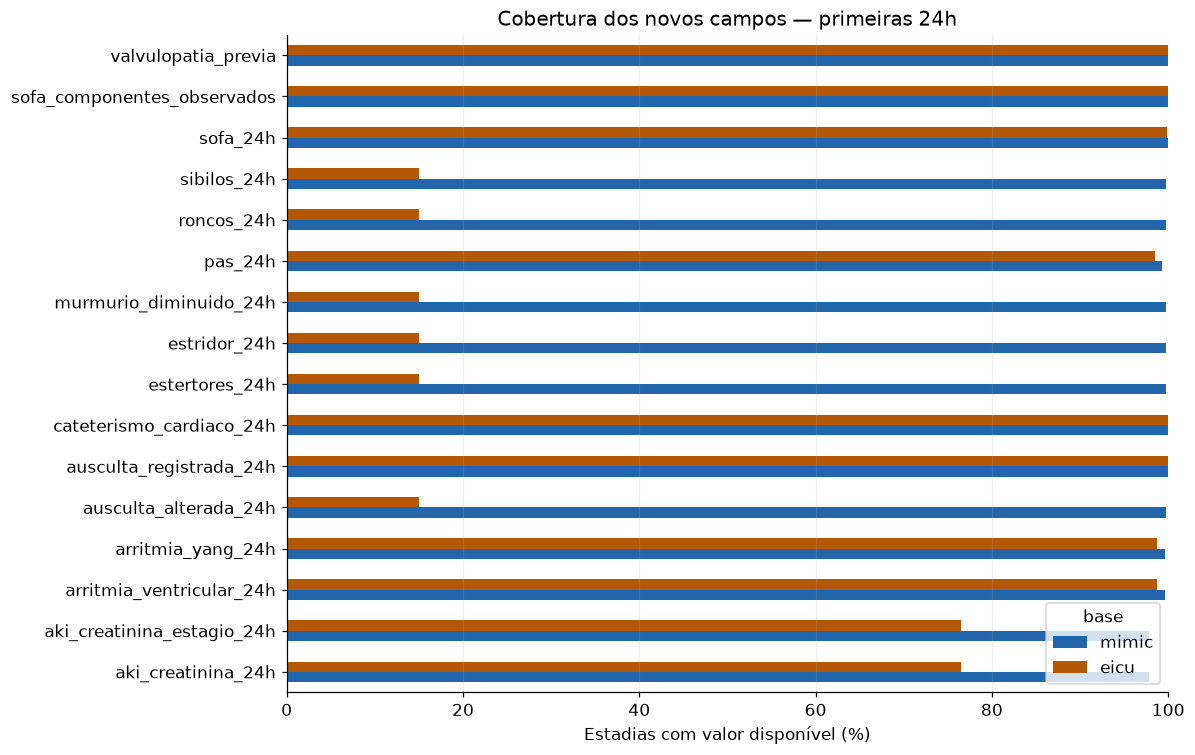

,base,variavel,n,fracao_ausente,p1,p50,p99
30,mimic,volume_infundido_24h,21549,0.142,36.786,1458.505,10110.702
31,mimic,diurese_total_24h,21549,0.058,10.000,1405.000,5880.700
55,mimic,aki_creatinina_estagio_24h,21549,0.022,0.000,0.000,3.000
57,mimic,sofa_24h,21549,0.000,0.000,6.000,17.000
58,mimic,sofa_componentes_observados,21549,0.000,3.000,5.000,6.000
100,eicu,volume_infundido_24h,13537,0.535,20.873,1140.000,7172.540
101,eicu,diurese_total_24h,13537,0.325,0.000,1404.000,6600.000
125,eicu,aki_creatinina_estagio_24h,13537,0.235,0.000,0.000,3.000
127,eicu,sofa_24h,13537,0.001,0.000,4.000,13.000
128,eicu,sofa_componentes_observados,13537,0.000,2.000,4.000,6.000


In [2]:
mapping = pd.read_csv(ROOT/'harmonizacao.csv')
display(mapping.loc[~mapping.incluida,['variavel','motivo']])
coverage = quality[quality.variavel.isin(NOVAS)].pivot(index='variavel',columns='base',values='fracao_ausente')
coverage = (1-coverage)*100
ax=coverage[['mimic','eicu']].plot.barh(figsize=(11,7),color=['#2166ac','#b35806'])
ax.set(xlim=(0,100),xlabel='Estadias com valor disponível (%)',ylabel='',title='Cobertura dos novos campos — primeiras 24h')
ax.grid(axis='x',alpha=.2);plt.tight_layout();plt.show()
display(quality[quality.variavel.isin(['sofa_24h','sofa_componentes_observados','aki_creatinina_estagio_24h',
    'volume_infundido_24h','diurese_total_24h'])][['base','variavel','n','fracao_ausente','p1','p50','p99']].round(3))


## 3. Classificação ajustada: MIMIC e eICU

O painel de 70 campos tem avaliação interna. O modelo de 65 campos foi treinado
separadamente no MIMIC e validado no eICU. AUC mede discriminação; Brier mede erro
das probabilidades. As barras de erro são IC95% por bootstrap de pacientes.


,perfil,base,modelo,corte,n,auc,auc_ic95_inf,auc_ic95_sup,auc_pr,brier,vpp,vpn
0,completo_ampliado,mimic,xgboost,3.55,4426,0.741,0.727,0.757,0.661,0.199,0.599,0.753
1,completo_ampliado,mimic,rede_neural,3.55,4426,0.748,0.734,0.762,0.666,0.196,0.616,0.757
2,completo_ampliado,mimic,xgboost,7.00,4426,0.758,0.739,0.778,0.402,0.120,0.304,0.918
3,completo_ampliado,mimic,rede_neural,7.00,4426,0.754,0.736,0.773,0.398,0.120,0.307,0.916
4,harmonizado,mimic,xgboost,3.55,4426,0.738,0.724,0.754,0.661,0.199,0.615,0.745
5,harmonizado,eicu,xgboost,3.55,13537,0.666,0.657,0.675,0.571,0.223,0.578,0.678
6,harmonizado,mimic,rede_neural,3.55,4426,0.741,0.728,0.755,0.658,0.198,0.601,0.747
7,harmonizado,eicu,rede_neural,3.55,13537,0.626,0.616,0.635,0.532,0.235,0.455,0.712
8,harmonizado,mimic,xgboost,7.00,4426,0.754,0.737,0.774,0.395,0.121,0.305,0.918
9,harmonizado,eicu,xgboost,7.00,13537,0.687,0.674,0.698,0.286,0.125,0.271,0.894


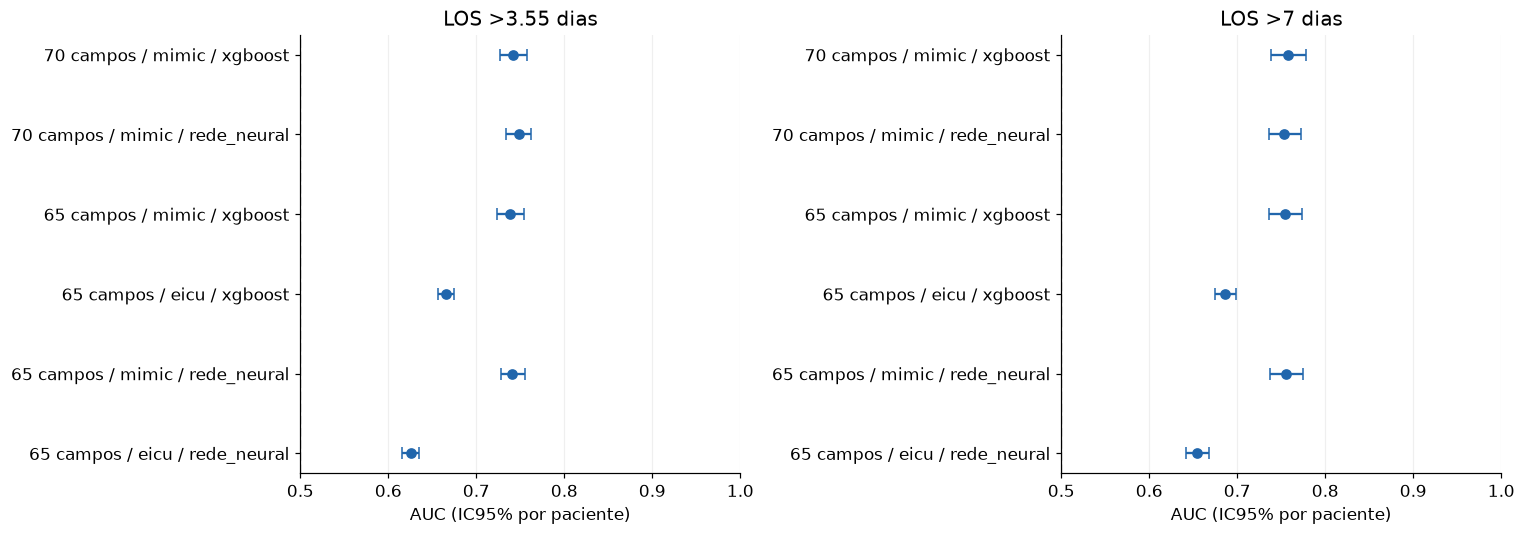

In [3]:
metrics=pd.concat([full,harm],ignore_index=True)
display(metrics[['perfil','base','modelo','corte','n','auc','auc_ic95_inf','auc_ic95_sup','auc_pr','brier','vpp','vpn']].round(3))
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,cut in zip(axes,[3.55,7.]):
    tab=metrics[metrics.corte.eq(cut)].copy()
    tab['rotulo']=tab.perfil.replace({'completo_ampliado':'70 campos','harmonizado':'65 campos'})+' / '+tab.base+' / '+tab.modelo
    pos=np.arange(len(tab))
    ax.errorbar(tab.auc,pos,xerr=[tab.auc-tab.auc_ic95_inf,tab.auc_ic95_sup-tab.auc],fmt='o',color='#2166ac',capsize=4)
    ax.set_yticks(pos,tab.rotulo);ax.invert_yaxis()
    ax.set(xlim=(.5,1),xlabel='AUC (IC95% por paciente)',title=f'LOS >{cut:g} dias')
    ax.axvline(.5,color='gray',ls='--');ax.grid(axis='x',alpha=.2)
plt.tight_layout();plt.show()


## 4. Antes e depois

Mesma partição interna e mesmas estadias. Esta comparação combina revisão da extração,
novas variáveis e ajuste de hiperparâmetros; não atribui todo ganho a um único fator.
A ablação mais abaixo isola o acréscimo de variáveis sob o mesmo ajuste XGBoost.


In [4]:
oldroot=Path('artefatos_protocolo_24h')
rows=[]
for profile,newfolder,oldfolder,base in [
    ('MIMIC: 54 → 70','completo_ampliado/interno','completo/interno','mimic'),
    ('eICU: 13 → 65','harmonizado/externo','comum/externo','eicu')]:
    for cut in [3.55,7.]:
        for model in ['xgboost','rede_neural']:
            key=f'{model}_{cut:g}d'
            a=pd.read_csv(ROOT/newfolder/key/'previsoes.csv')
            b=pd.read_csv(oldroot/oldfolder/key/'previsoes.csv')
            old=pd.read_csv(oldroot/oldfolder/key/'metricas.csv').iloc[0]
            new=pd.read_csv(ROOT/newfolder/key/'metricas.csv').iloc[0]
            delta=diferenca_pareada(a,b,bootstrap=500)
            rows.append(dict(comparacao=profile,modelo=model,corte=cut,auc_antes=old.auc,auc_agora=new.auc,
                delta=delta['delta_completo_menos_variante'],ic95_inf=delta['ic95_inf'],ic95_sup=delta['ic95_sup']))
before_after=pd.DataFrame(rows)
before_after.to_csv(ROOT/'antes_depois_pareado.csv',index=False)
display(before_after.round(4))


,comparacao,modelo,corte,auc_antes,auc_agora,delta,ic95_inf,ic95_sup
0,MIMIC: 54 → 70,xgboost,3.55,0.7310,0.7412,0.0102,0.0026,0.0178
1,MIMIC: 54 → 70,rede_neural,3.55,0.7299,0.7480,0.0181,0.0082,0.0285
2,MIMIC: 54 → 70,xgboost,7.00,0.7579,0.7576,-0.0003,-0.0090,0.0088
3,MIMIC: 54 → 70,rede_neural,7.00,0.7321,0.7537,0.0216,0.0095,0.0336
4,eICU: 13 → 65,xgboost,3.55,0.6201,0.6658,0.0458,0.0356,0.0552
5,eICU: 13 → 65,rede_neural,3.55,0.6137,0.6262,0.0126,0.0013,0.0231
6,eICU: 13 → 65,xgboost,7.00,0.6371,0.6865,0.0494,0.0351,0.0622
7,eICU: 13 → 65,rede_neural,7.00,0.6216,0.6543,0.0327,0.0180,0.0467


## 5. MLP versus XGBoost

Delta = AUC MLP − AUC XGBoost. O mesmo sorteio de pacientes é usado para os dois.
Intervalo contendo zero indica diferença incerta nesta amostra, não equivalência comprovada.


In [5]:
paired=[]
for profile,place in [('completo_ampliado','interno'),('harmonizado','interno'),('harmonizado','externo')]:
    paired.append(pd.read_csv(ROOT/profile/place/'rede_neural_vs_xgboost.csv').assign(perfil=profile,avaliacao=place))
display(pd.concat(paired,ignore_index=True).round(4))
params=[]
for folder in (ROOT/'completo_ampliado/buscas').iterdir():
    fit=joblib.load(folder/'ajuste.joblib')
    model=fit['modelo'].named_steps['modelo']
    model=getattr(model,'regressor_',model)
    params.append({'modelo_alvo':folder.name,'score_cv':fit['score_cv'],
        'epocas_modelo_final':getattr(model,'n_iter_',np.nan),
        'limite_epocas':getattr(model,'max_iter',np.nan),
        'parametros':json.dumps(fit['params'],ensure_ascii=False)})
display(pd.DataFrame(params))


,corte,auc_rede,auc_xgboost,delta_auc,delta_ic95_inf,delta_ic95_sup,perfil,avaliacao
0,3.55,0.7480,0.7412,0.0068,-0.0016,0.0155,completo_ampliado,interno
1,7.00,0.7537,0.7576,-0.0039,-0.0140,0.0062,completo_ampliado,interno
2,3.55,0.7410,0.7383,0.0027,-0.0059,0.0108,harmonizado,interno
3,7.00,0.7553,0.7545,0.0008,-0.0088,0.0099,harmonizado,interno
4,3.55,0.6262,0.6658,-0.0396,-0.0482,-0.0317,harmonizado,externo
5,7.00,0.6543,0.6865,-0.0322,-0.0424,-0.0202,harmonizado,externo


,modelo_alvo,score_cv,epocas_modelo_final,limite_epocas,parametros
0,rede_neural_3.55d,0.731476,110.0,200.0,"{""modelo__learning_rate_init"": 0.0005, ""modelo..."
1,rede_neural_7d,0.753002,71.0,200.0,"{""modelo__learning_rate_init"": 0.0005, ""modelo..."
2,regressao_rede_neural,-2.753798,131.0,200.0,"{""modelo__regressor__learning_rate_init"": 0.00..."
3,regressao_xgboost,-2.740056,NaN,NaN,"{""modelo__regressor__subsample"": 0.8, ""modelo_..."
4,xgboost_3.55d,0.734205,NaN,NaN,"{""modelo__subsample"": 0.8, ""modelo__reg_lambda..."
5,xgboost_7d,0.750615,NaN,NaN,"{""modelo__subsample"": 0.8, ""modelo__reg_lambda..."


## 6. Curvas ROC

Teste interno do painel completo e validação externa do harmonizado.
Os números são calculados nas mesmas previsões usadas nas tabelas de métricas.


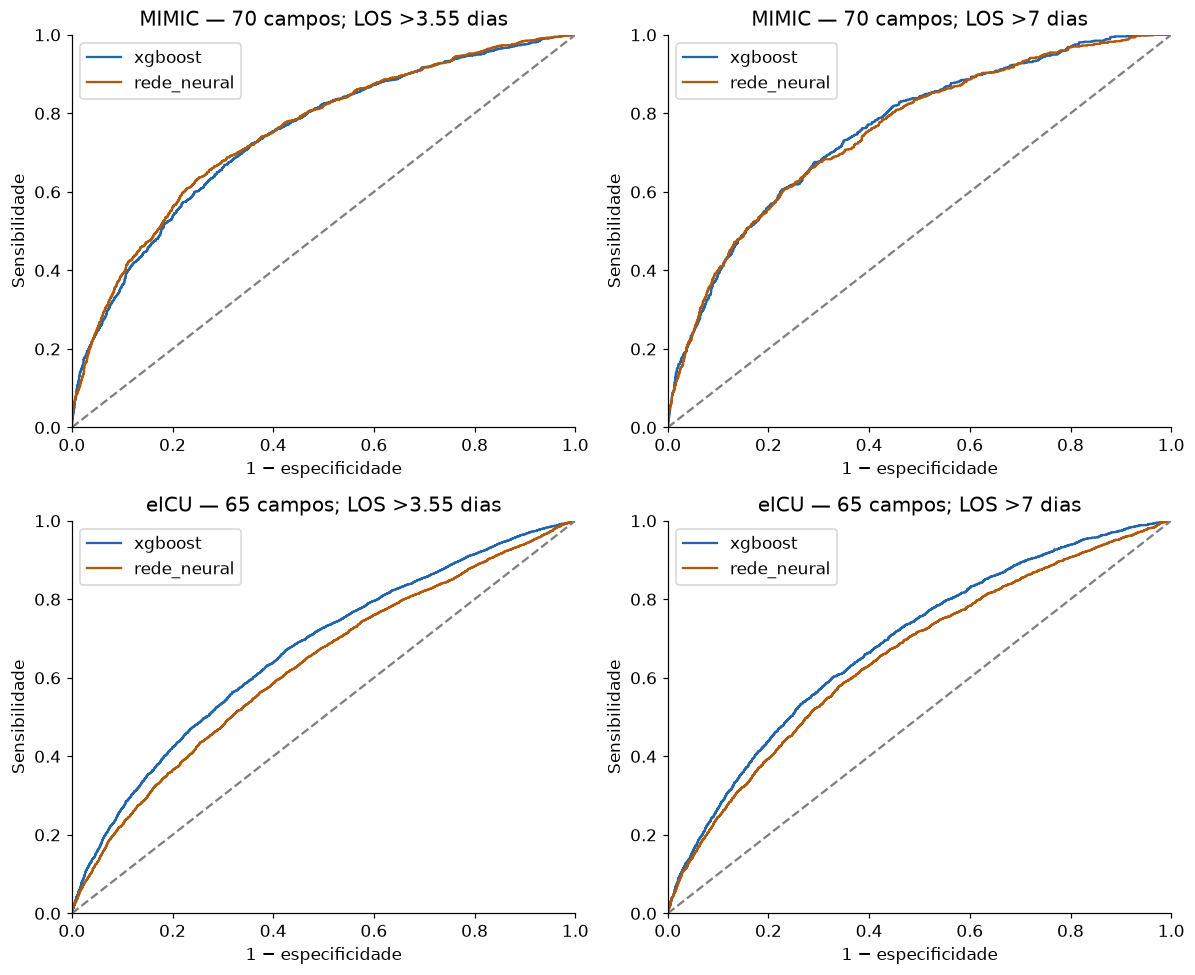

In [6]:
fig,axes=plt.subplots(2,2,figsize=(11,9))
for row,(profile,place,title) in enumerate([('completo_ampliado','interno','MIMIC — 70 campos'),('harmonizado','externo','eICU — 65 campos')]):
    for col,cut in enumerate([3.55,7.]):
        ax=axes[row,col]
        for model in CORES:
            pred=pd.read_csv(ROOT/profile/place/f'{model}_{cut:g}d/previsoes.csv')
            fpr,tpr,_=roc_curve(pred.alvo,pred.probabilidade)
            ax.plot(fpr,tpr,label=model,color=CORES[model])
        ax.plot([0,1],[0,1],'--',color='gray');ax.legend()
        ax.set(xlabel='1 − especificidade',ylabel='Sensibilidade',title=f'{title}; LOS >{cut:g} dias',xlim=(0,1),ylim=(0,1))
plt.tight_layout();plt.show()


## 7. Calibração e DCA

A diagonal representa probabilidades calibradas. A DCA compara benefício líquido
retrospectivo por limiar; não comprova benefício assistencial. Para legibilidade,
mostra-se a DCA até 0,8, com eixo vertical de −0,1 a 0,5; CSVs mantêm a faixa completa.


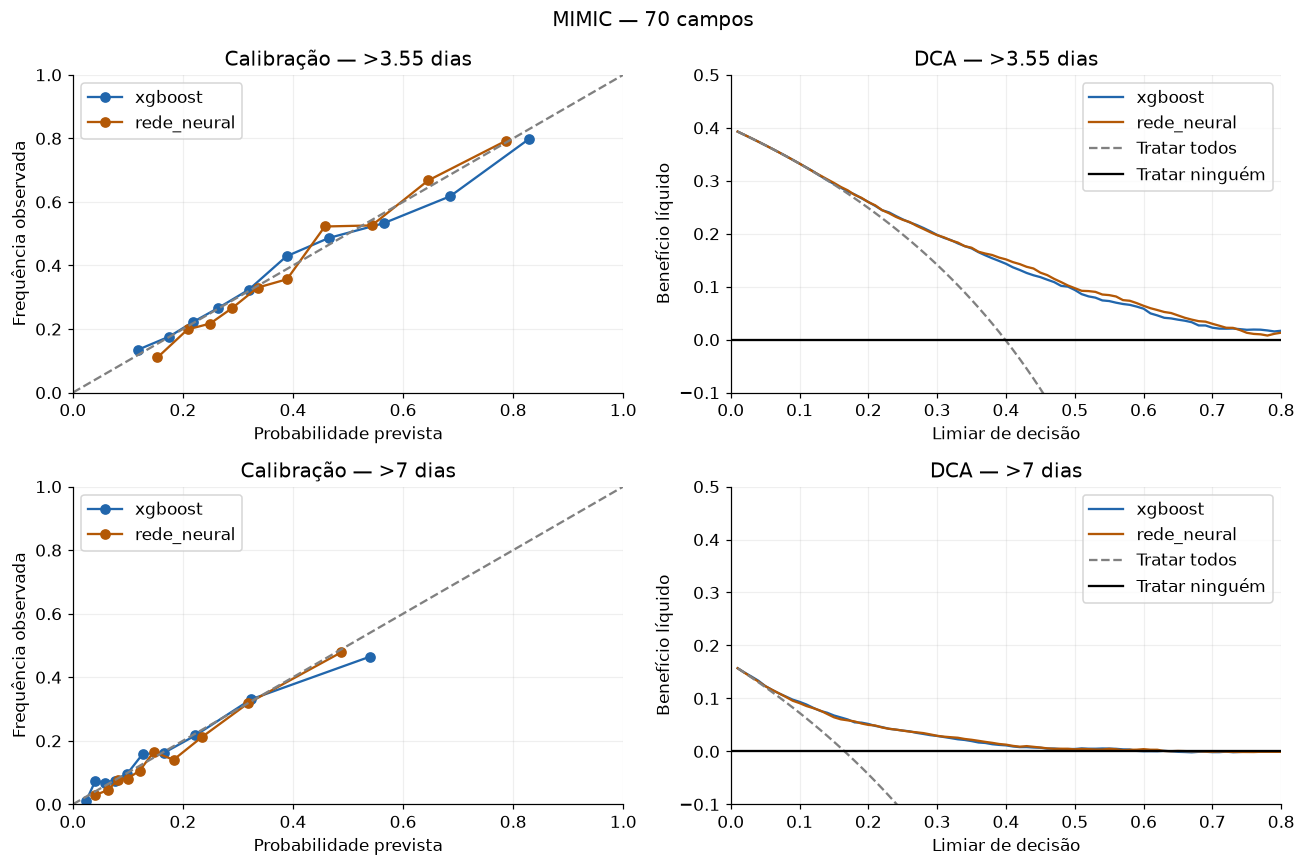

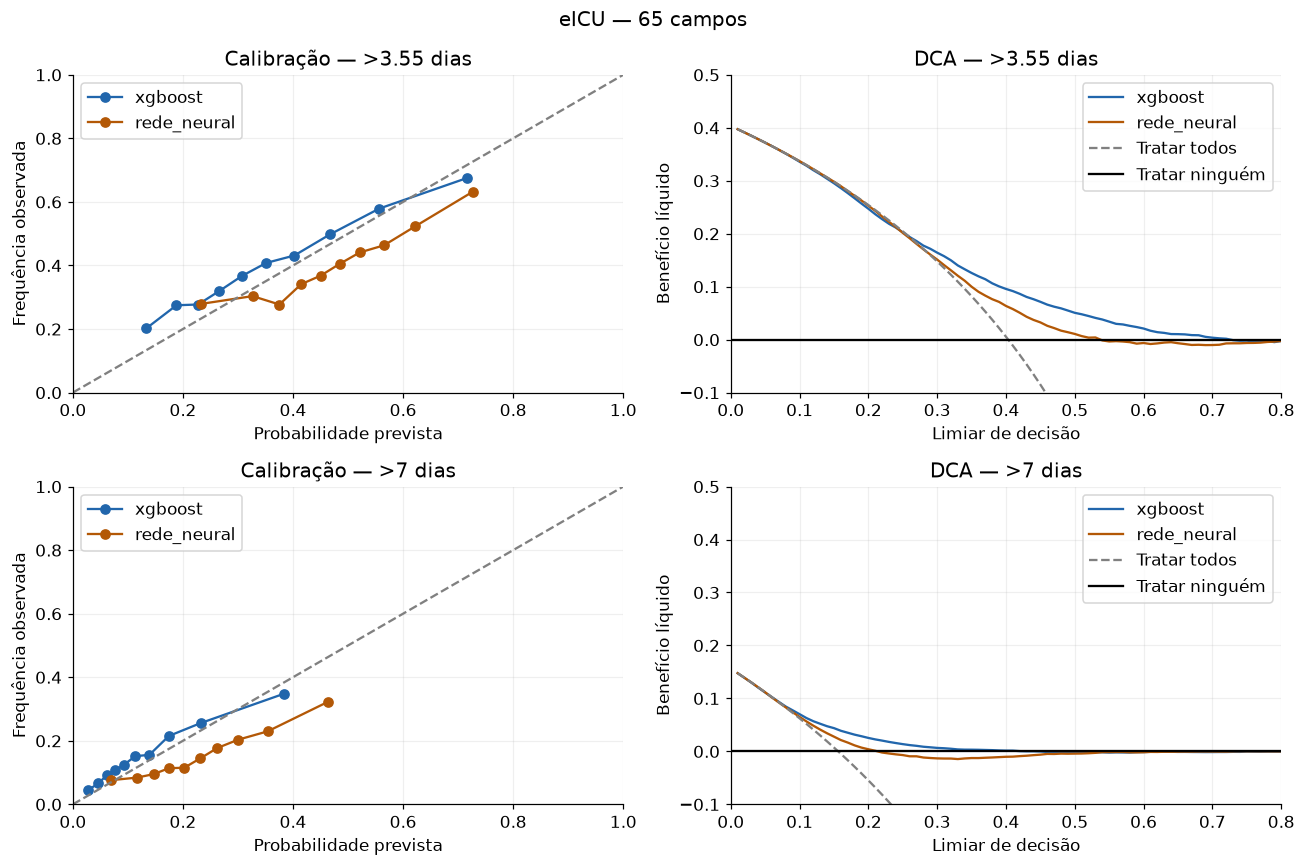

In [7]:
for profile,place,title in [('completo_ampliado','interno','MIMIC — 70 campos'),('harmonizado','externo','eICU — 65 campos')]:
    fig,axes=plt.subplots(2,2,figsize=(12,8))
    for row,cut in enumerate([3.55,7.]):
        for model in CORES:
            folder=ROOT/profile/place/f'{model}_{cut:g}d'
            cal=pd.read_csv(folder/'calibracao.csv');dc=pd.read_csv(folder/'dca.csv')
            axes[row,0].plot(cal.probabilidade_media,cal.frequencia_observada,'o-',label=model,color=CORES[model])
            axes[row,1].plot(dc.limiar,dc.modelo,label=model,color=CORES[model])
        axes[row,0].plot([0,1],[0,1],'--',color='gray')
        axes[row,0].set(xlim=(0,1),ylim=(0,1),xlabel='Probabilidade prevista',ylabel='Frequência observada',title=f'Calibração — >{cut:g} dias')
        axes[row,1].plot(dc.limiar,dc.tratar_todos,'--',color='gray',label='Tratar todos')
        axes[row,1].axhline(0,color='black',label='Tratar ninguém')
        axes[row,1].set(xlim=(0,.8),ylim=(-.1,.5),xlabel='Limiar de decisão',ylabel='Benefício líquido',title=f'DCA — >{cut:g} dias')
        for ax in axes[row]: ax.legend();ax.grid(alpha=.2)
    fig.suptitle(title);plt.tight_layout();plt.show()


## 8. SHAP: quais variáveis o XGBoost utilizou

Importância absoluta média em até 500 estadias do teste, semente 42. Não informa
direção do efeito, causalidade ou utilidade clínica isolada. Variáveis correlacionadas
podem repartir importância. Novos campos aparecem em laranja.


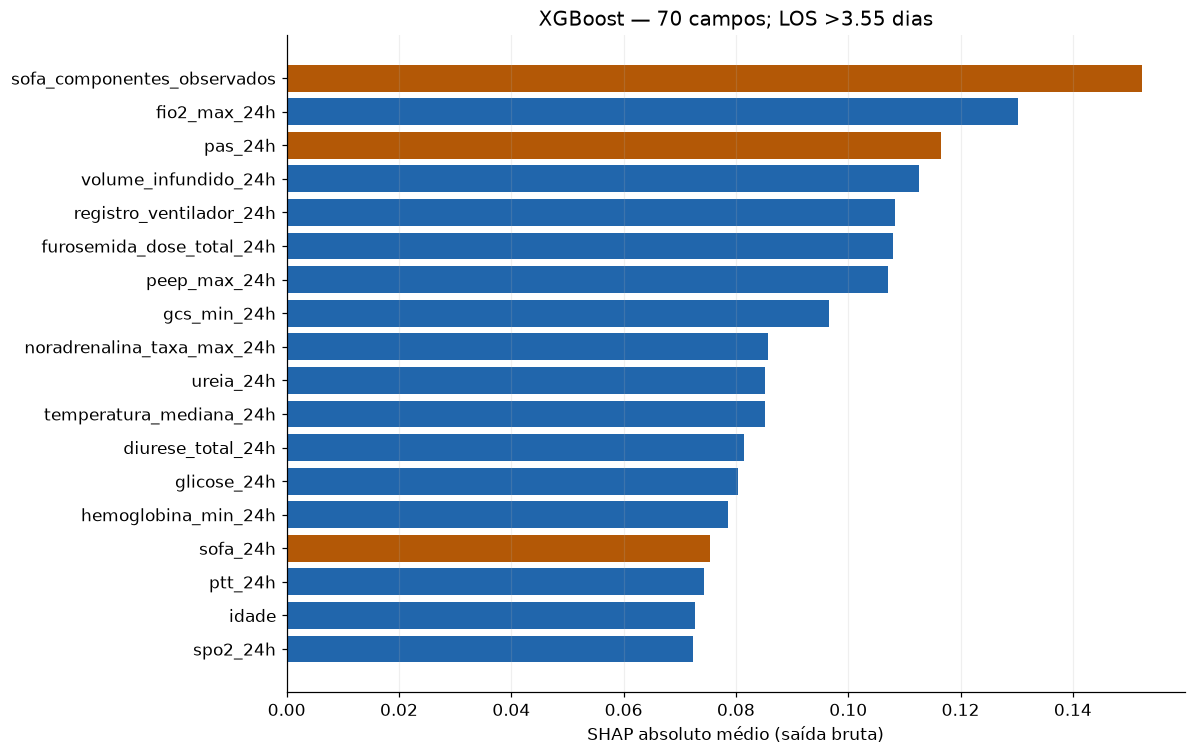

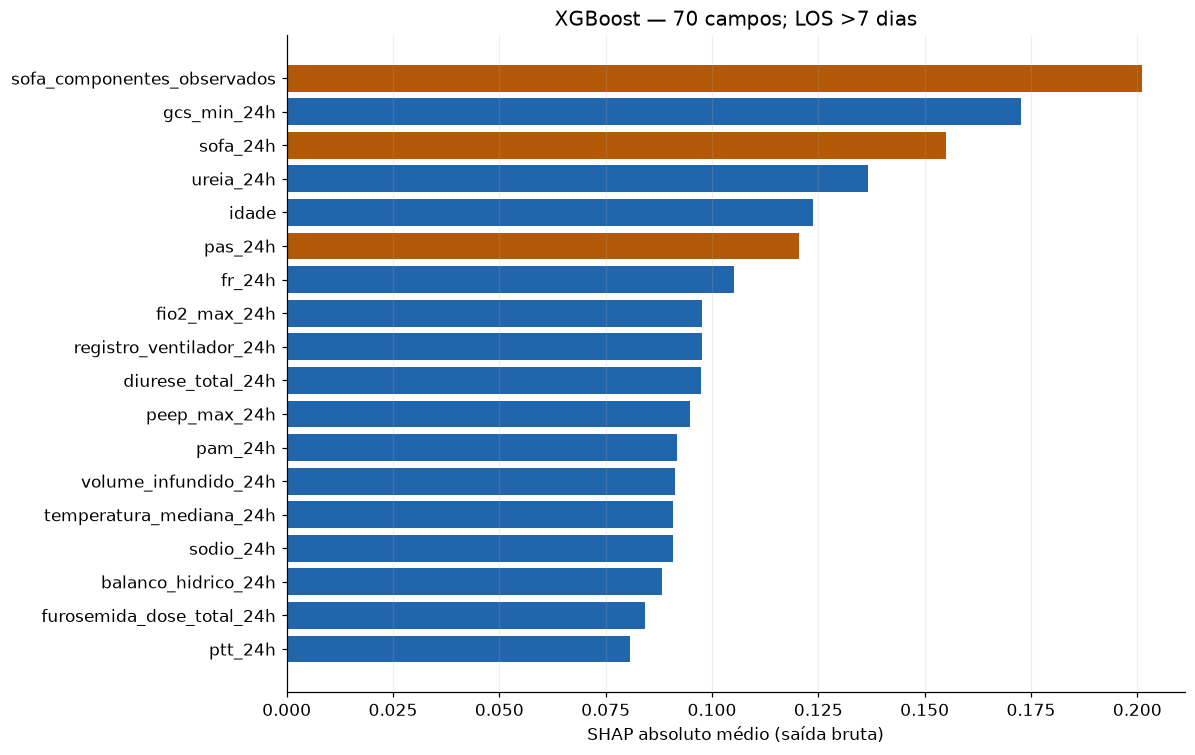

In [8]:
for cut in [3.55,7.]:
    sh=pd.read_csv(ROOT/'completo_ampliado/interno'/f'xgboost_{cut:g}d/shap.csv')
    sh['nome']=sh.variavel.str.replace('num__','',regex=False).str.replace('cat__','',regex=False)
    top=sh.head(18).sort_values('shap_absoluto_medio')
    fig,ax=plt.subplots(figsize=(11,7))
    ax.barh(top.nome,top.shap_absoluto_medio,color=['#b35806' if n in NOVAS else '#2166ac' for n in top.nome])
    ax.set(xlabel='SHAP absoluto médio (saída bruta)',title=f'XGBoost — 70 campos; LOS >{cut:g} dias')
    ax.grid(axis='x',alpha=.2);plt.tight_layout();plt.show()


## 9. Ablações: o que cada alteração acrescentou

Seis variantes XGBoost, mantendo os hiperparâmetros selecionados no painel completo.
Filtro de ausência e imputação são aprendidos no treino de cada parte. “Sem eventos”
remove também SOFA e sua contagem, porque SOFA incorpora urina e vasopressores.
A coluna CV orienta a escolha exploratória; o teste não é usado para selecionar variante.


,variante,corte,auc_cv,auc,auc_ic95_inf,auc_ic95_sup,brier,n_preditores_transformados
0,completo_ampliado,3.55,0.7341,0.7412,0.7270,0.7573,0.1986,77
1,sem_novas_variaveis,3.55,0.7306,0.7360,0.7219,0.7510,0.2003,61
2,sem_entradas_saidas,3.55,0.7193,0.7255,0.7122,0.7410,0.2037,55
3,sem_mais_30pct_ausencia,3.55,0.7287,0.7339,0.7204,0.7490,0.2009,68
4,indicadores_de_ausencia,3.55,0.7354,0.7444,0.7304,0.7591,0.1976,121
5,laboratorios_maximos,3.55,0.7337,0.7401,0.7261,0.7551,0.1987,77
6,completo_ampliado,7.00,0.7504,0.7576,0.7389,0.7776,0.1199,77
7,sem_novas_variaveis,7.00,0.7450,0.7568,0.7380,0.7777,0.1191,61
8,sem_entradas_saidas,7.00,0.7337,0.7426,0.7243,0.7623,0.1209,55
9,sem_mais_30pct_ausencia,7.00,0.7481,0.7423,0.7212,0.7619,0.1224,68


,variante,corte,delta_completo_menos_variante,ic95_inf,ic95_sup
0,sem_novas_variaveis,3.55,0.0052,0.0001,0.0101
1,sem_entradas_saidas,3.55,0.0157,0.0067,0.0231
2,sem_mais_30pct_ausencia,3.55,0.0073,0.0014,0.0127
3,indicadores_de_ausencia,3.55,-0.0032,-0.0078,0.0012
4,laboratorios_maximos,3.55,0.0011,-0.0034,0.0056
5,sem_novas_variaveis,7.00,0.0009,-0.0061,0.0076
6,sem_entradas_saidas,7.00,0.0150,0.0049,0.0265
7,sem_mais_30pct_ausencia,7.00,0.0153,0.0082,0.0222
8,indicadores_de_ausencia,7.00,0.0005,-0.0057,0.0059
9,laboratorios_maximos,7.00,0.0014,-0.0052,0.0077


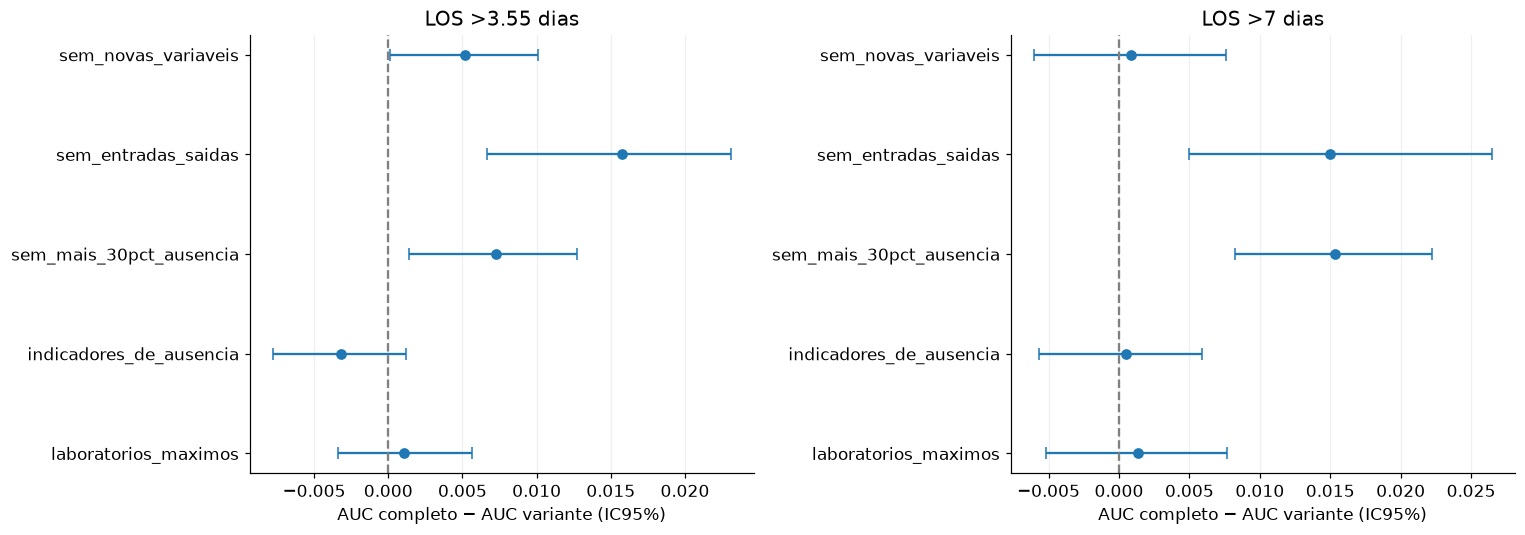

,corte,variante,auc_cv,auc
0,7.00,indicadores_de_ausencia,0.7513,0.7571
1,3.55,indicadores_de_ausencia,0.7354,0.7444


In [9]:
ab=pd.read_csv(ROOT/'ablacoes/comparacao.csv')
display(ab[['variante','corte','auc_cv','auc','auc_ic95_inf','auc_ic95_sup','brier','n_preditores_transformados']].round(4))
delta=pd.read_csv(ROOT/'ablacoes/diferencas_pareadas.csv')
display(delta.round(4))
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,cut in zip(axes,[3.55,7.]):
    d=delta[delta.corte.eq(cut)]
    ax.errorbar(d.delta_completo_menos_variante,np.arange(len(d)),
        xerr=[d.delta_completo_menos_variante-d.ic95_inf,d.ic95_sup-d.delta_completo_menos_variante],fmt='o',capsize=4)
    ax.set_yticks(np.arange(len(d)),d.variante);ax.invert_yaxis();ax.axvline(0,color='gray',ls='--')
    ax.set(xlabel='AUC completo − AUC variante (IC95%)',title=f'LOS >{cut:g} dias')
    ax.grid(axis='x',alpha=.2)
plt.tight_layout();plt.show()
display(pd.read_csv(ROOT/'ablacoes/escolha_por_cv.csv')[['corte','variante','auc_cv','auc']].round(4))


## 10. Previsão do número de dias

Regressão de LOS observado, transformado com log1p no treino. MAE/RMSE em dias;
R² pode ser negativo. São modelos diferentes dos classificadores e incluem saídas por morte.


,perfil,base,modelo,n,mae,rmse,r2
0,completo_ampliado,mimic,xgboost,4426,2.535,4.996,0.137
1,completo_ampliado,mimic,rede_neural,4426,2.548,5.042,0.121
2,harmonizado,mimic,xgboost,4426,2.542,4.991,0.138
3,harmonizado,eicu,xgboost,13537,2.746,5.021,0.048
4,harmonizado,mimic,rede_neural,4426,2.563,5.009,0.132
5,harmonizado,eicu,rede_neural,13537,2.778,5.102,0.017


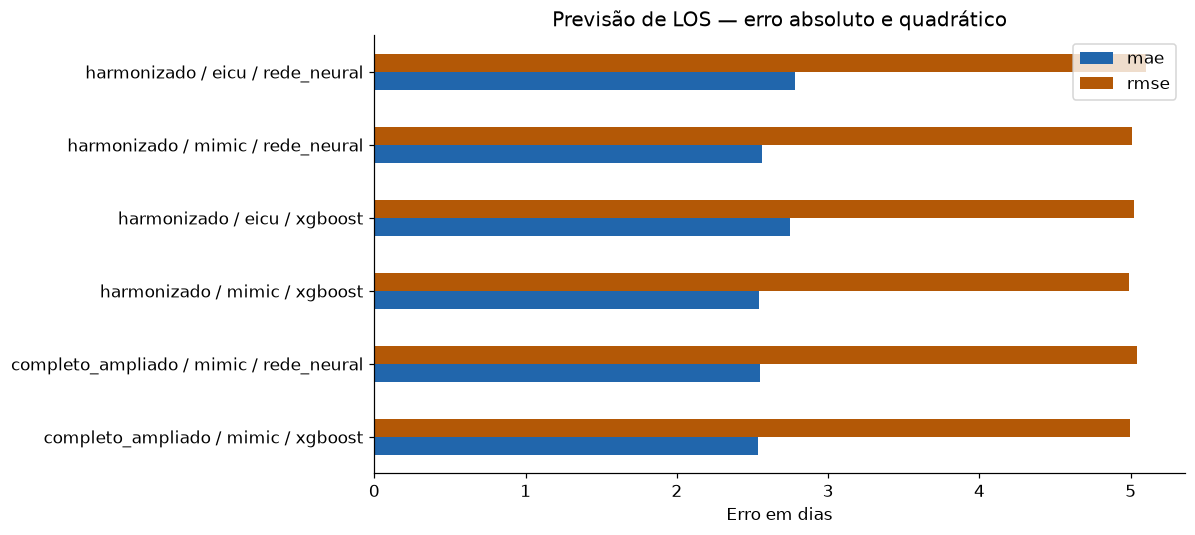

In [10]:
reg=pd.concat([pd.read_csv(ROOT/profile/'regressao.csv').assign(perfil=profile)
    for profile in ['completo_ampliado','harmonizado']],ignore_index=True)
display(reg[['perfil','base','modelo','n','mae','rmse','r2']].round(3))
tab=reg.copy();tab['rotulo']=tab.perfil+' / '+tab.base+' / '+tab.modelo
ax=tab.set_index('rotulo')[['mae','rmse']].plot.barh(figsize=(11,5),color=['#2166ac','#b35806'])
ax.set(xlabel='Erro em dias',ylabel='',title='Previsão de LOS — erro absoluto e quadrático')
plt.tight_layout();plt.show()


## 11. Yang aproximado — experimento separado

IC principal, sobreviventes hospitalares, primeira UTI da internação, incluindo
estadias ≤24h. Dez conceitos importantes, com diagnósticos retrospectivos e tratamentos
até 48h. Esta análise não é reprodução exata do artigo nem modelo prospectivo de 24h.
Não deve substituir o resultado principal ou ser escolhida apenas por apresentar AUC maior.

No artigo, **0,922 é Random Forest no treino**; XGBoost teve 0,861 interna e 0,815
externa. A comparação direta é limitada por versão, população, extração e protocolo.


In [11]:
yang=pd.read_csv(ROOT/'yang_aproximado/comparacao.csv')
lim=json.loads((ROOT/'yang_aproximado/limites.json').read_text(encoding='utf-8'))
print(f"Coorte aproximada: {lim['n_mimic']} estadias MIMIC e {lim['n_eicu']} eICU.")
display(yang[['base','modelo','n','prevalencia','auc','auc_ic95_inf','auc_ic95_sup','brier']].round(3))
for line in lim['limites']: print('•',line)


Coorte aproximada: 1492 estadias MIMIC e 3744 eICU.


,base,modelo,n,prevalencia,auc,auc_ic95_inf,auc_ic95_sup,brier
0,mimic,xgboost,296,0.287,0.720,0.651,0.782,0.179
1,eicu,xgboost,3744,0.251,0.660,0.642,0.681,0.183
2,mimic,rede_neural,296,0.287,0.741,0.673,0.808,0.181
3,eicu,rede_neural,3744,0.251,0.676,0.658,0.696,0.177


• Aproximação de 10 preditores importantes; não reprodução exata dos 41 candidatos ou nove algoritmos
• MIMIC 3.1, não 2.2
• AKI somente critério de creatinina; SOFA adaptado, com cobertura explícita
• Diagnósticos retrospectivos podem não estar disponíveis em 24h; não utilizar como modelo prospectivo
• Diurético e cateterismo até 48h; evidência registrada varia entre as bases
• Split por paciente preservado; não selecionar sobreviventes na população principal


## 12. Sensibilidade por óbito, hospitais e convergência

A sensibilidade separa o mesmo modelo por desfecho hospitalar. A auditoria por
hospital mostra cobertura de fontes; métricas de hospitais pequenos são descritivas.
Avisos de convergência da MLP não são ocultados.


In [12]:
sensitivity=[]
for cut in [3.55,7.]:
    sensitivity.append(pd.read_csv(ROOT/'completo_ampliado/interno'/f'xgboost_{cut:g}d/sensibilidade_obitos.csv').assign(corte=cut))
display(pd.concat(sensitivity)[['corte','grupo','n','auc','brier','vpp','vpn']].round(3))
hosp=pd.read_csv(ROOT/'cobertura_por_hospital.csv')
cols=[c for c in hosp if c.startswith('cobertura_')]
display(hosp[hosp.base.eq('eicu')][cols].agg(['min','median','max']).T.round(3))
warnings=[]
for f in ROOT.glob('**/avisos.csv'):
    w=pd.read_csv(f)
    if not w.empty:
        warnings.append({'busca':str(f.parent.relative_to(ROOT)),'n_avisos':len(w),'exemplo':w.aviso.iloc[0]})
display(pd.DataFrame(warnings))
print('Resultados individuais e modelos permanecem locais, excluídos do Git.')


,corte,grupo,n,auc,brier,vpp,vpn
0,3.55,sobreviventes,3770,0.747,0.191,0.596,0.767
1,3.55,obitos_hospitalares,656,0.633,0.244,0.608,0.594
0,7.00,sobreviventes,3770,0.770,0.105,0.295,0.929
1,7.00,obitos_hospitalares,656,0.626,0.206,0.329,0.803


,min,median,max
cobertura_aki_creatinina_estagio_24h,0.000,0.823,1.00
cobertura_sofa_24h,0.839,1.000,1.00
cobertura_ausculta_alterada_24h,0.000,0.000,1.00
cobertura_diurese_total_24h,0.000,0.746,1.00
cobertura_volume_infundido_24h,0.000,0.130,1.00
cobertura_troponina_t_max_24h,0.000,0.000,0.75


,busca,n_avisos,exemplo
0,yang_aproximado\buscas\rede_neural,15,Stochastic Optimizer: Maximum iterations (200)...
1,harmonizado\buscas\rede_neural_3.55d,3,Stochastic Optimizer: Maximum iterations (200)...
2,harmonizado\buscas\rede_neural_7d,3,Stochastic Optimizer: Maximum iterations (200)...
3,harmonizado\buscas\regressao_rede_neural,3,Stochastic Optimizer: Maximum iterations (200)...
4,completo_ampliado\buscas\rede_neural_3.55d,3,Stochastic Optimizer: Maximum iterations (200)...
5,completo_ampliado\buscas\rede_neural_7d,3,Stochastic Optimizer: Maximum iterations (200)...
6,completo_ampliado\buscas\regressao_rede_neural,3,Stochastic Optimizer: Maximum iterations (200)...


Resultados individuais e modelos permanecem locais, excluídos do Git.


## Leitura dos resultados

Considere conjuntamente AUC, ICs pareados, calibração, cobertura e estabilidade externa.
As ablações medem a contribuição neste ajuste e nesta amostra; não provam que uma
variável é universalmente útil ou inútil. SHAP alto no artigo não garante o mesmo
ranking aqui. O eICU testa transferência entre bases, incluindo diferenças de registro.

Os arquivos de evidência estão em `artefatos_protocolo_24h/experimentos_v3/`.
Os resultados anteriores de 54/13 campos permanecem preservados em `completo/` e `comum/`.

**Resultados desta execução (19/11/2026):** as diferenças internas entre MLP e
XGBoost incluem zero nos ICs pareados. No eICU, XGBoost teve maior AUC nos dois
cortes. A ablação estima ganho pequeno das novas variáveis para >3,55 dias e
incerto para >7 dias; retirar entradas/saídas junto com SOFA prejudicou os dois alvos.
Os intervalos exploratórios não foram corrigidos por múltiplas comparações.

A quantidade de componentes observados do SOFA liderou o SHAP do XGBoost.
Isso sugere que o modelo usa também o processo de medição/registro, além dos valores
clínicos; não significa que medir mais cause internação prolongada. Ausculta tem
cobertura muito menor no eICU, o que limita a transferência dos modelos.

O benchmark aproximado usou IC principal como `seq_num=1` no MIMIC e prioridade
`primary` no eICU. As coortes de 1.492/3.744 estadias diferem das 5.744/4.056
publicadas; essa aproximação não recuperou o desempenho publicado e não deve ser
apresentada como reprodução do artigo.
